omega_ring        : [1. 0. 0.]
omega_rel (to ring): [0.    1.755 0.959]
omega_rod          : [1.    1.755 0.959]
axial part w.u     : 0.7174  q1_dot sin q2 = 0.7174
saved the figure


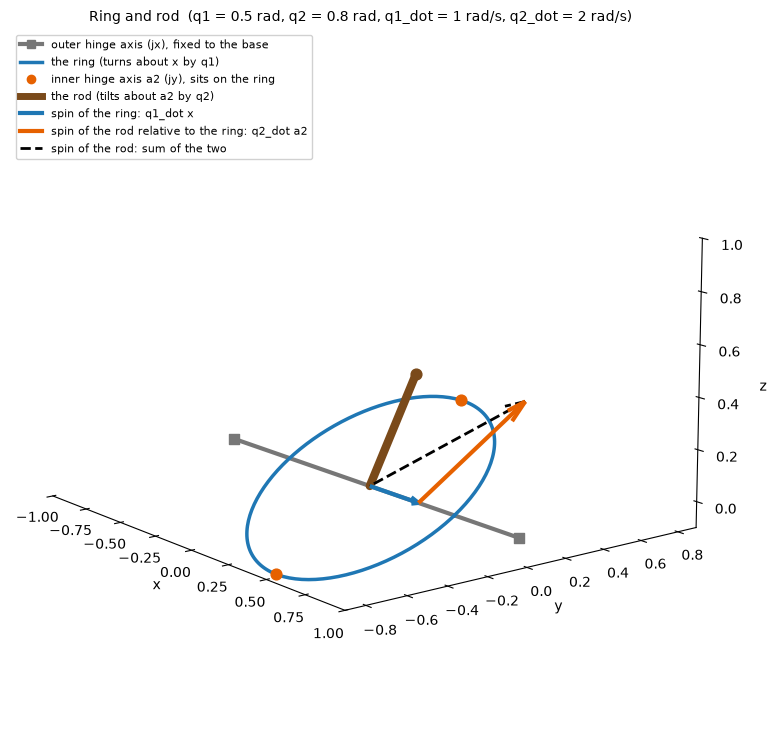

In [1]:
import os
from datetime import datetime

import numpy as np  # type: ignore
import matplotlib.pyplot as plt  # type: ignore
from matplotlib.lines import Line2D  # type: ignore

RESULT_DIR = os.path.join(os.getcwd(), "result")
os.makedirs(RESULT_DIR, exist_ok=True)
TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")

# ---------------------------------------------------------------
# STEP 1: pose and rotation matrices
#   What we have: joint angles q1, q2 (rad) and rates q1_dot, q2_dot (rad/s)
#   What we want: the inner hinge axis a2 and the rod direction u in the lab frame
#   Why: a2 = R_x(q1) y_hat (the inner axis rides on the ring), u = R_x(q1) R_y(q2) z_hat
#   a2 = (0, cos q1, sin q1)
#   u  = (sin q2, -sin q1 cos q2, cos q1 cos q2)
# ---------------------------------------------------------------
q1, q2 = 0.5, 0.8
q1_dot, q2_dot = 1.0, 2.0


def Rx(q):
    c, s = np.cos(q), np.sin(q)
    return np.array([[1, 0, 0], [0, c, -s], [0, s, c]])


def Ry(q):
    c, s = np.cos(q), np.sin(q)
    return np.array([[c, 0, s], [0, 1, 0], [-s, 0, c]])


x_hat = np.array([1.0, 0.0, 0.0])
y_hat = np.array([0.0, 1.0, 0.0])
z_hat = np.array([0.0, 0.0, 1.0])
a2 = Rx(q1) @ y_hat
u = Rx(q1) @ Ry(q2) @ z_hat

# ---------------------------------------------------------------
# STEP 2: the three angular velocities
#   What we have: x_hat, a2, q1_dot, q2_dot
#   What we want: spin of the ring, spin of the rod relative to the ring, and their sum
#   Why: omega_rod = omega_ring + omega_rod_relative_to_ring
#   omega_ring = q1_dot x_hat
#   omega_rel  = q2_dot a2
#   omega_rod  = omega_ring + omega_rel
# ---------------------------------------------------------------
w_ring = q1_dot * x_hat
w_rel = q2_dot * a2
w_rod = w_ring + w_rel
print("omega_ring        :", np.round(w_ring, 3))
print("omega_rel (to ring):", np.round(w_rel, 3))
print("omega_rod          :", np.round(w_rod, 3))
print("axial part w.u     :", round(float(w_rod @ u), 4), " q1_dot sin q2 =", round(q1_dot * np.sin(q2), 4))

# ---------------------------------------------------------------
# STEP 3: draw the gimbal
#   What we have: x_hat, a2, u and the three spins
#   What we want: a picture of the fixed frame, the ring, the rod and the arrows
#   Why: to see what "ring" and "rod relative to ring" mean
#   ring = circle in the plane spanned by x_hat and a2
# ---------------------------------------------------------------
BLUE, ORANGE, BLACK, GRAY, BROWN = "#1f77b4", "#e66100", "#000000", "#777777", "#7a4a1a"
R_RING = 0.55
t = np.linspace(0, 2 * np.pi, 200)
ring = R_RING * (np.outer(np.cos(t), x_hat) + np.outer(np.sin(t), a2))

fig = plt.figure(figsize=(9, 7.5))
ax = fig.add_subplot(111, projection="3d")

ax.plot([-0.95, 0.95], [0, 0], [0, 0], color=GRAY, lw=3)
for sgn in (-1, 1):
    ax.scatter(*(sgn * 0.95 * x_hat), color=GRAY, marker="s", s=60)
ax.plot(ring[:, 0], ring[:, 1], ring[:, 2], color=BLUE, lw=2.5)
for sgn in (-1, 1):
    ax.scatter(*(sgn * R_RING * a2), color=ORANGE, s=60)
ax.plot([0, u[0]], [0, u[1]], [0, u[2]], color=BROWN, lw=6, solid_capstyle="round")
ax.scatter(*u, color=BROWN, s=60)

SC = 0.32
ax.quiver(0, 0, 0, *(SC * w_ring), color=BLUE, lw=3, arrow_length_ratio=0.15)
ax.quiver(*(SC * w_ring), *(SC * w_rel), color=ORANGE, lw=3, arrow_length_ratio=0.15)
ax.quiver(0, 0, 0, *(SC * w_rod), color=BLACK, lw=2, linestyle="--", arrow_length_ratio=0.12)

ax.set_xlim(-1, 1)
ax.set_ylim(-0.9, 0.9)
ax.set_zlim(-0.1, 1.0)
ax.set_box_aspect((1, 0.9, 0.6))
ax.grid(False)
for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
    axis.pane.set_visible(False)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.view_init(elev=14, azim=-38)

handles = [
    Line2D([0], [0], color=GRAY, lw=3, marker="s", label="outer hinge axis (jx), fixed to the base"),
    Line2D([0], [0], color=BLUE, lw=2.5, label="the ring (turns about x by q1)"),
    Line2D([0], [0], color=ORANGE, lw=0, marker="o", label="inner hinge axis a2 (jy), sits on the ring"),
    Line2D([0], [0], color=BROWN, lw=5, label="the rod (tilts about a2 by q2)"),
    Line2D([0], [0], color=BLUE, lw=3, label="spin of the ring: q1_dot x"),
    Line2D([0], [0], color=ORANGE, lw=3, label="spin of the rod relative to the ring: q2_dot a2"),
    Line2D([0], [0], color=BLACK, lw=2, ls="--", label="spin of the rod: sum of the two"),
]
ax.legend(handles=handles, loc="upper left", fontsize=8, framealpha=0.9)
ax.set_title(
    "Ring and rod  (q1 = 0.5 rad, q2 = 0.8 rad, q1_dot = 1 rad/s, q2_dot = 2 rad/s)",
    fontsize=10,
)

plt.tight_layout()
out_path = os.path.join(RESULT_DIR, f"gimbal_ring_rod_{TIMESTAMP}.png")
plt.savefig(out_path, dpi=200)
print("saved the figure")
plt.show()